# 01. CBC data exploration

This notebook explores the tabular side of the project: the complete blood count (CBC) values parsed from the AneRBC dataset. It runs from files that are already in the repository, so you do not need the 7.5 GB image download.

**What you will see**

1. A 100-row sample of the data (`data/sample/cbc_sample.csv`).
2. The full 1000-row parsed table (`artifacts/master.parquet`) and a parser coverage check.
3. How much signal each CBC feature carries on its own.
4. Why the CBC columns are not independent measurements.
5. Differential missingness, a leakage channel hidden in the reports.
6. A 5-fold LightGBM baseline retrained from the table and checked against the saved predictions.

Run the cells from top to bottom. The whole notebook takes about a minute. Figures are saved to `docs/figures/` in a light and a dark version.

## Setup

`import src` has to come first. It sets `OMP_NUM_THREADS=1` and loads LightGBM before PyTorch, which avoids a hard crash on macOS caused by two copies of the OpenMP runtime (see `src/__init__.py`).

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]

import src  # noqa: F401  Keep this first: it sets OMP_NUM_THREADS and loads LightGBM before PyTorch.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_auc_score

import viz

FIG_DIR = ROOT / "docs" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

## 1. The sample dataset

`data/sample/cbc_sample.csv` has 100 rows (50 healthy, 50 anemic) with the parsed CBC values. A blank cell means the field could not be read from the report or failed a plausibility check. The label `y` is 1 for anemic and 0 for healthy. `data/sample/README.md` documents every column and the dataset license.

In [2]:
sample = pd.read_csv(ROOT / "data" / "sample" / "cbc_sample.csv")
print(f"{sample.shape[0]} rows x {sample.shape[1]} columns")
print(sample["y"].map({0: "healthy", 1: "anemic"}).value_counts().to_string(), "\n")
print("Share of rows with a missing value, by column:")
print((sample.isna().mean() * 100).round(0).astype(int).astype(str).add("%").to_string())
sample.head()

100 rows x 16 columns
y
healthy    50
anemic     50 

Share of rows with a missing value, by column:
sample_id        0%
cls              0%
y                0%
group            0%
fold             0%
MCV              2%
MCH              6%
MCHC             6%
RDW             31%
RBC              0%
WBC              1%
PLT              6%
MPV             27%
HGB              2%
HCT              2%
sex_inferred    39%


,sample_id,cls,y,group,fold,MCV,MCH,MCHC,RDW,RBC,WBC,PLT,MPV,HGB,HCT,sex_inferred
0,001_h,h,0,001_h,3,90.1,29.0,32.2,12.8,4.65,7.39,331.0,11.0,13.5,41.9,0.0
1,003_h,h,0,003_h,2,85.6,30.1,35.1,12.5,5.89,6.41,180.0,13.2,17.7,50.4,1.0
2,010_h,h,0,010_h,0,90.4,28.8,31.9,13.2,4.16,8.58,278.0,11.8,12.0,37.6,0.0
3,012_h,h,0,012_h,4,76.1,24.5,32.2,NaN,6.24,7.73,295.0,9.8,15.3,47.5,1.0
4,023_h,h,0,023_h,4,86.7,29.8,34.3,NaN,4.20,4.54,221.0,13.1,12.5,36.4,0.0


## 2. The full parsed table

`artifacts/master.parquet` is the table that every model arm reads. It has one row per sample with the parsed CBC values, the label, a patient group key and a fold index. It was built by `python -m src.build_dataset`.

The parser has a recorded coverage target for each field (`EXPECTED_COVERAGE` in `src/config.py`). A large shortfall would mean an alias or a unit anchor stopped working. The `img_path` column points to files on the author's machine, so we drop it.

In [3]:
from src.config import EXPECTED_COVERAGE, UNIVARIATE_AUROC

master = pd.read_parquet(ROOT / "artifacts" / "master.parquet").drop(columns="img_path")
FEATURES = list(EXPECTED_COVERAGE)

coverage = pd.DataFrame(
    {
        "coverage": master[FEATURES].notna().mean(),
        "expected": pd.Series(EXPECTED_COVERAGE),
    }
)
coverage["shortfall"] = coverage["expected"] - coverage["coverage"]
print(f"{len(master)} samples, {master['group'].nunique()} patient groups, folds: {sorted(master['fold'].unique())}")
coverage.round(3)

1000 samples, 1000 patient groups, folds: [0, 1, 2, 3, 4]


,coverage,expected,shortfall
MCV,0.981,0.981,0.000
MCH,0.929,0.929,0.000
MCHC,0.942,0.942,0.000
RDW,0.632,0.630,-0.002
RBC,0.955,0.955,0.000
WBC,0.981,0.981,0.000
PLT,0.968,0.967,-0.001
MPV,0.682,0.682,0.000
HGB,0.979,0.979,0.000
HCT,0.955,0.955,0.000


## 3. Signal in each feature on its own

For each feature we compute a raw AUROC over the samples where it parses (complete cases). The value is oriented so that 0.5 is chance and higher is better, and the `direction` column says which way the feature moves in anemic samples. The README reports the same numbers (`UNIVARIATE_AUROC` in `src/config.py`).

**How to read it.** Hemoglobin (HGB) is the clinical definition of anemia, yet it ranks below all three red-cell indices (MCH, MCV, MCHC) and RDW. The label in this dataset comes from a pathologist's smear reading (microcytic, hypochromic), not from a hemoglobin threshold, so the indices that describe cell size and color line up with it better.

In [4]:
rows = []
for f in FEATURES:
    d = master[["y", f]].dropna()
    auc = roc_auc_score(d["y"], d[f])
    rows.append(
        {
            "feature": f,
            "n_complete": len(d),
            "auroc": max(auc, 1 - auc),
            "direction": "lower in anemic" if auc < 0.5 else "higher in anemic",
            "recorded_in_config": UNIVARIATE_AUROC[f],
        }
    )
uni = pd.DataFrame(rows).sort_values("auroc", ascending=False).reset_index(drop=True)
uni["diff_vs_recorded"] = uni["auroc"] - uni["recorded_in_config"]
print(f"Largest gap to the recorded values: {uni['diff_vs_recorded'].abs().max():.4f}")
uni

Largest gap to the recorded values: 0.0036


,feature,n_complete,auroc,direction,recorded_in_config,diff_vs_recorded
0,MCH,929,0.696,lower in anemic,0.697,-8.531e-04
1,MCV,981,0.690,lower in anemic,0.690,-1.115e-04
2,MCHC,942,0.658,lower in anemic,0.659,-5.851e-04
3,RDW,632,0.638,higher in anemic,0.634,3.642e-03
4,HGB,979,0.610,lower in anemic,0.611,-1.375e-03
5,HCT,955,0.598,lower in anemic,0.598,2.122e-04
6,PLT,968,0.590,higher in anemic,0.591,-8.614e-04
7,MPV,682,0.557,lower in anemic,0.561,-3.541e-03
8,RBC,955,0.542,higher in anemic,0.542,8.340e-05
9,WBC,981,0.519,higher in anemic,0.522,-2.991e-03


In [5]:
healthy = master[(master["y"] == 0) & master["HGB"].notna()]
share_low = (healthy["HGB"] < 12).mean()
print(f"{share_low:.1%} of the {len(healthy)} healthy-labeled samples with a hemoglobin value have HGB below 12 g/dL")

52.3% of the 488 healthy-labeled samples with a hemoglobin value have HGB below 12 g/dL


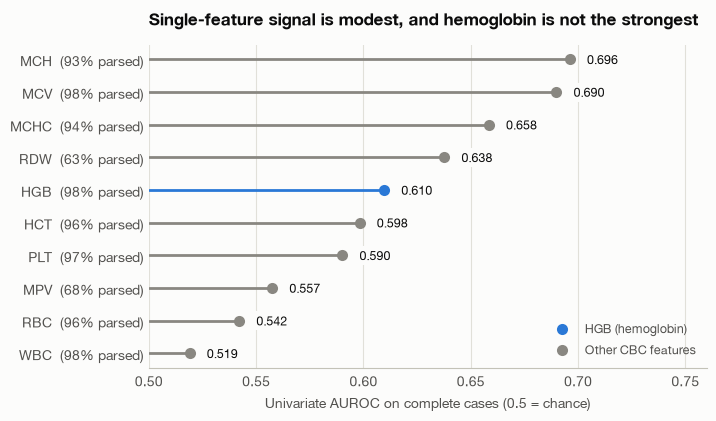

In [6]:
def draw_univariate(t):
    fig, ax = viz.new_axes(t, (7.2, 4.2), grid="x")
    d = uni.iloc[::-1].reset_index(drop=True)  # strongest feature on top
    for i, r in d.iterrows():
        accent = r["feature"] == "HGB"
        color = t["blue"] if accent else t["muted"]
        ax.plot([0.5, r["auroc"]], [i, i], color=color, linewidth=2, solid_capstyle="round", zorder=2)
        ax.plot(r["auroc"], i, "o", color=color, markersize=8, markeredgewidth=0, zorder=3)
        ax.text(r["auroc"] + 0.008, i, f"{r['auroc']:.3f}", va="center", color=t["ink"], fontsize=9,
                bbox=dict(facecolor=t["surface"], edgecolor="none", pad=1.5), zorder=4)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([f"{f}  ({c / len(master):.0%} parsed)" for f, c in zip(d["feature"], d["n_complete"])])
    ax.set_xlim(0.5, 0.76)
    ax.set_xlabel("Univariate AUROC on complete cases (0.5 = chance)")
    viz.title(ax, t, "Single-feature signal is modest, and hemoglobin is not the strongest")
    viz.legend(
        ax, t,
        [
            viz.dot(t["blue"], "HGB (hemoglobin)"),
            viz.dot(t["muted"], "Other CBC features"),
        ],
        loc="lower right",
    )
    return fig


viz.show_and_save(draw_univariate, "univariate-auroc", FIG_DIR)

## 4. The red-cell indices are algebraically linked

An analyzer computes MCH, MCV and MCHC from hemoglobin (HGB), hematocrit (HCT) and the red cell count (RBC):

- MCH (pg) = 10 x HGB (g/dL) / RBC (10^6 per uL)
- MCV (fL) = 10 x HCT (%) / RBC (10^6 per uL)
- MCHC (g/dL) = 100 x HGB (g/dL) / HCT (%)

So the CBC panel carries less independent information than its ten columns suggest. To check, we recompute each index from the other columns and compare it with the value parsed from the report. A high correlation confirms the relationship. The remaining error comes from rounding and from OCR noise in the reports.

In [7]:
implied = pd.DataFrame(
    {
        "MCH": 10 * master["HGB"] / master["RBC"],
        "MCV": 10 * master["HCT"] / master["RBC"],
        "MCHC": 100 * master["HGB"] / master["HCT"],
    }
)
rows = []
for idx in implied:
    both = pd.concat([implied[idx], master[idx]], axis=1, keys=["implied", "parsed"]).dropna()
    rel_err = ((both["implied"] - both["parsed"]).abs() / both["parsed"]).median()
    rows.append(
        {
            "index": idx,
            "n_rows": len(both),
            "pearson_r": both["implied"].corr(both["parsed"]),
            "median_relative_error": rel_err,
        }
    )
pd.DataFrame(rows).set_index("index")

,n_rows,pearson_r,median_relative_error
index,,,
MCH,882,0.944,1.169e-03
MCV,924,0.939,3.669e-04
MCHC,908,0.850,9.030e-04


## 5. Differential missingness

The CBC reports are not consistent about which fields they contain, and that inconsistency correlates with the label. A model that can see a missing-value pattern can learn the report template instead of physiology. The chart shows, for each field, the share of reports where the value parsed, split by class.

We also score one binary flag, "RDW is missing", as if it were a predictor. If a flag that carries no clinical information still beats chance, the missingness is a leakage channel. The README documents this as trap 3 and recommends imputing without missing-value indicator columns.

In [8]:
cov = (
    master.groupby("cls")[FEATURES]
    .agg(lambda s: s.notna().mean())
    .T.rename(columns={"h": "healthy", "a": "anemic"})
)
cov["gap"] = (cov["healthy"] - cov["anemic"]).abs()
cov = cov.sort_values("gap", ascending=False)

for f in ("RDW", "MPV"):
    flag = master[f].isna().astype(int)
    print(f"AUROC of the '{f} is missing' flag alone: {roc_auc_score(master['y'], flag):.3f}")
cov.round(3)

AUROC of the 'RDW is missing' flag alone: 0.554
AUROC of the 'MPV is missing' flag alone: 0.550


cls,anemic,healthy,gap
RDW,0.578,0.686,0.108
MPV,0.632,0.732,0.100
MCH,0.910,0.948,0.038
RBC,0.968,0.942,0.026
WBC,0.994,0.968,0.026
HCT,0.964,0.946,0.018
MCV,0.988,0.974,0.014
MCHC,0.936,0.948,0.012
HGB,0.982,0.976,0.006
PLT,0.968,0.968,0.000


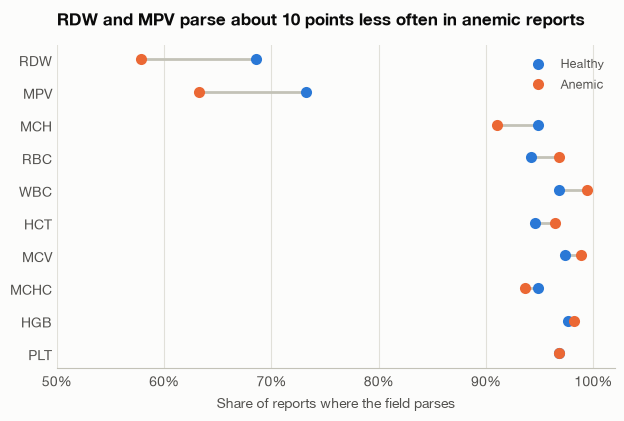

In [9]:
def draw_missingness(t):
    fig, ax = viz.new_axes(t, (7.2, 4.2), grid="x")
    d = cov.iloc[::-1].reset_index()
    for i, r in d.iterrows():
        ax.plot([r["healthy"], r["anemic"]], [i, i], color=t["axis"], linewidth=2, zorder=1)
        for key, color in (("healthy", t["blue"]), ("anemic", t["orange"])):
            ax.plot(r[key], i, "o", color=color, markersize=8, markeredgewidth=0, zorder=3)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels(d["index"])
    ax.set_xlim(0.5, 1.02)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xlabel("Share of reports where the field parses")
    viz.title(ax, t, "RDW and MPV parse about 10 points less often in anemic reports")
    viz.legend(
        ax, t,
        [
            viz.dot(t["blue"], "Healthy"),
            viz.dot(t["orange"], "Anemic"),
        ],
        loc="upper right",
    )
    return fig


viz.show_and_save(draw_missingness, "missingness", FIG_DIR)

## 6. Retrain the LightGBM baseline

This uses the project's own code path (`src.train.train_one_fold`) on the stored folds. LightGBM receives raw NaNs because it handles them natively. Early stopping watches an inner split of the training rows, so the outer fold is never used for fitting.

We deliberately do not call `run_arm`, because it would overwrite the committed predictions in `artifacts/preds/`. Instead we compare our fresh out-of-fold predictions with the saved ones.

In [10]:
from src.config import FEATURES_DEFAULT, N_FOLDS, SEED
from src.metrics import aggregate_folds, summarize
from src.train import load_master, train_one_fold

df = load_master()
oof = np.full(len(df), np.nan)
per_fold = []
for fold in range(N_FOLDS):
    is_val = df["fold"] == fold
    p = train_one_fold("lgbm", df[~is_val], df[is_val], FEATURES_DEFAULT, SEED + fold)
    oof[is_val.to_numpy()] = p
    per_fold.append(summarize(df.loc[is_val, "y"].to_numpy(), np.asarray(p)))
    print(f"fold {fold}: " + "  ".join(f"{k}={v:.3f}" for k, v in per_fold[-1].items()))

print("\nretrained :", aggregate_folds(per_fold))

fold 0: auroc=0.737  auprc=0.691  ece=0.128
fold 1: auroc=0.655  auprc=0.598  ece=0.099
fold 2: auroc=0.688  auprc=0.636  ece=0.126
fold 3: auroc=0.711  auprc=0.660  ece=0.127


fold 4: auroc=0.661  auprc=0.597  ece=0.003

retrained : {'auroc': '0.690 +/- 0.031', 'auprc': '0.636 +/- 0.036', 'ece': '0.097 +/- 0.048'}


In [11]:
saved = pd.read_csv(ROOT / "artifacts" / "preds" / "lgbm.csv")
saved_per_fold = [summarize(g["y"].to_numpy(), g["pred"].to_numpy()) for _, g in saved.groupby("fold")]
print("saved     :", aggregate_folds(saved_per_fold))

aligned = saved.set_index("sample_id").loc[df["sample_id"], "pred"].to_numpy()
print(f"\nLargest absolute difference between retrained and saved predictions: {np.abs(oof - aligned).max():.2e}")

saved     : {'auroc': '0.690 +/- 0.031', 'auprc': '0.636 +/- 0.036', 'ece': '0.097 +/- 0.048'}

Largest absolute difference between retrained and saved predictions: 5.55e-17


## Takeaways

- The parsed CBC table is clean enough to model, and the parser meets its recorded coverage targets.
- The tabular signal is modest. A well-regularized LightGBM lands near 0.69 AUROC. The README's ablations report that the extra columns add almost nothing beyond the three red-cell indices, which is consistent with section 4, where those indices are shown to be derived from each other.
- Which fields a report contains differs by class (section 5), so the pipeline imputes missing values without adding missing-value indicator columns.
- The saved predictions can be regenerated from the repository, which is what makes the comparisons in notebook 02 checkable.

**Next:** `02_results_and_comparisons.ipynb` compares all seven model arms with paired bootstrap confidence intervals.